In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import BertTokenizer, BertModel, ViTModel
from torchvision import transforms
from PIL import Image
from tqdm import tqdm

from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import os

DATA_DIR = "/content/drive/MyDrive/Datasets/multimodal_fake_news_detection"

TRAIN_CSV = os.path.join(DATA_DIR, "twitter_dataset.csv")
IMAGE_DIR = os.path.join(DATA_DIR, "images")

CHECKPOINT_DIR = os.path.join(DATA_DIR, "checkpoints")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# Load full training CSV
full_df = pd.read_csv(TRAIN_CSV)

# Drop rows with missing critical fields
full_df = full_df.dropna(
    subset=["post_text", "image_id", "label"]
).reset_index(drop=True)

# Group key (prevents image leakage)
groups = full_df["image_id"]

# ---------------------------
# Train+Temp (80%) / Test (20%)
# ---------------------------
gss_1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_temp_idx, test_idx = next(gss_1.split(full_df, groups=groups))

train_temp_df = full_df.iloc[train_temp_idx].reset_index(drop=True)
test_df       = full_df.iloc[test_idx].reset_index(drop=True)

# ---------------------------
# Train (80%) / Val (20%) from Train+Temp
# ---------------------------
groups_temp = train_temp_df["image_id"]

gss_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(gss_2.split(train_temp_df, groups=groups_temp))

train_df = train_temp_df.iloc[train_idx].reset_index(drop=True)
val_df   = train_temp_df.iloc[val_idx].reset_index(drop=True)

# Optional: save splits
train_df.to_csv("/content/train_split.csv", index=False)
val_df.to_csv("/content/val_split.csv", index=False)
test_df.to_csv("/content/test_split.csv", index=False)

print("Group-aware Train / Val / Test split completed")
print(f"Train size: {len(train_df)}")
print(f"Val size:   {len(val_df)}")
print(f"Test size:  {len(test_df)}")


Group-aware Train / Val / Test split completed
Train size: 8631
Val size:   2919
Test size:  2121


In [ ]:
class MultimodalDataset(Dataset):
    def __init__(self, csv_path, image_dir, max_len=128):
        self.df = pd.read_csv(csv_path).dropna(subset=["post_text", "image_id", "label"])
        self.image_dir = image_dir
        self.max_len = max_len

        self.tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize([0.5]*3, [0.5]*3)
        ])

        self.label_map = {"real": 0, "fake": 1}

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        encoding = self.tokenizer(
            row["post_text"],
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt"
        )

        # Strip whitespace from image_id before constructing the path
        img_path = os.path.join(self.image_dir, row["image_id"].strip() + ".jpg")
        image = Image.open(img_path).convert("RGB")
        image = self.transform(image)

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "image": image,
            "label": self.label_map[row["label"]]
        }

In [ ]:
class MultimodalEncoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.bert = BertModel.from_pretrained("bert-base-uncased")
        self.vit = ViTModel.from_pretrained("google/vit-base-patch16-224")

        # Freeze ViT completely
        for p in self.vit.parameters():
            p.requires_grad = False

        # Fine-tune only top 2 BERT layers
        for name, p in self.bert.named_parameters():
            if "encoder.layer.10" in name or "encoder.layer.11" in name:
                p.requires_grad = True
            else:
                p.requires_grad = False

    def forward(self, input_ids, attention_mask, image):
        text_feat = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask
        ).last_hidden_state[:, 0, :]

        img_feat = self.vit(pixel_values=image).last_hidden_state[:, 0, :]

        # Text-dominant fusion
        fused = torch.cat([text_feat, 0.5 * img_feat], dim=1)
        return fused


In [ ]:
encoder = MultimodalEncoder().to(device)
encoder.eval()


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Some weights of ViTModel were not initialized from the model checkpoint at google/vit-base-patch16-224 and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


MultimodalEncoder(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, element

In [ ]:
def extract_embeddings(dataloader, model):
    features, labels = [], []

    with torch.no_grad():
        for batch in tqdm(dataloader):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            images = batch["image"].to(device)

            emb = model(input_ids, attention_mask, images)
            features.append(emb.cpu().numpy())
            labels.extend(batch["label"])

    return np.vstack(features), np.array(labels)


In [ ]:
train_dataset = MultimodalDataset("/content/train_split.csv", IMAGE_DIR)
val_dataset   = MultimodalDataset("/content/val_split.csv", IMAGE_DIR)
test_dataset  = MultimodalDataset("/content/test_split.csv", IMAGE_DIR)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=8, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=8, shuffle=False)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [ ]:
X_train, y_train = extract_embeddings(train_loader, encoder)
X_val,   y_val   = extract_embeddings(val_loader, encoder)
X_test,  y_test  = extract_embeddings(test_loader, encoder)


100%|██████████| 266/266 [01:25<00:00,  3.13it/s]


In [ ]:
svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(
        C=1.0,
        class_weight="balanced",
        max_iter=5000
    ))
])

svm.fit(X_train, y_train)


Pipeline(steps=[('scaler', StandardScaler()),
                ('svm', LinearSVC(class_weight='balanced', max_iter=5000))])

In [ ]:
def evaluate(model, X, y, name="Set"):
    preds = model.predict(X)
    acc = accuracy_score(y, preds)
    p, r, f, _ = precision_recall_fscore_support(y, preds, average="binary")
    cm = confusion_matrix(y, preds)

    print(f"\n{name} Results")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {p:.4f}")
    print(f"Recall   : {r:.4f}")
    print(f"F1-score : {f:.4f}")
    print("Confusion Matrix:")
    print(cm)

evaluate(svm, X_val, y_val, "Validation")
evaluate(svm, X_test, y_test, "Test")



Validation Results
Accuracy : 0.7475
Precision: 0.7365
Recall   : 0.9866
F1-score : 0.8434
Confusion Matrix:
[[ 197  710]
 [  27 1985]]

Test Results
Accuracy : 0.9543
Precision: 0.9540
Recall   : 0.9673
F1-score : 0.9606
Confusion Matrix:
[[ 841   57]
 [  40 1183]]


Visualizing Validation Set Results...


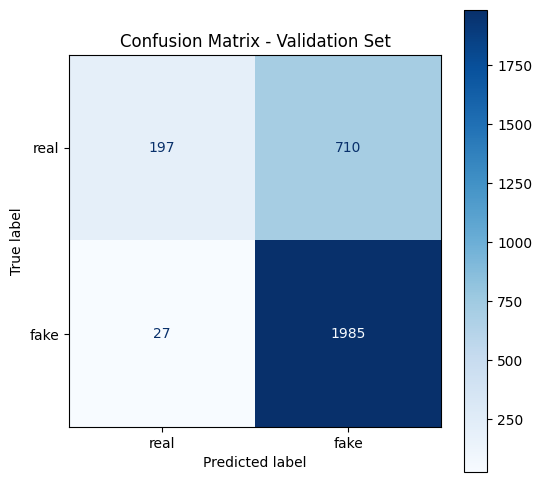


Classification Report - Validation Set:
              precision    recall  f1-score   support

        real       0.88      0.22      0.35       907
        fake       0.74      0.99      0.84      2012

    accuracy                           0.75      2919
   macro avg       0.81      0.60      0.60      2919
weighted avg       0.78      0.75      0.69      2919


Visualizing Test Set Results...


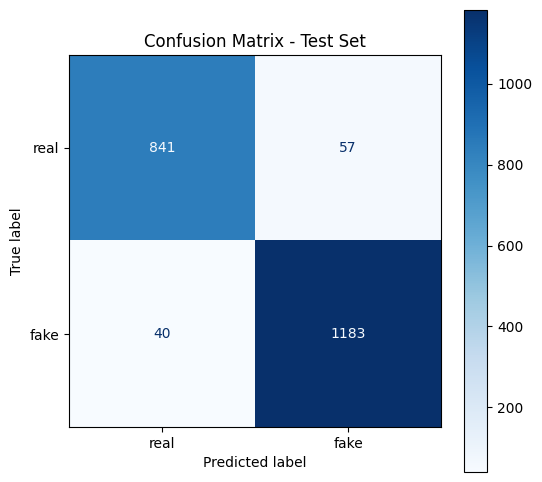


Classification Report - Test Set:
              precision    recall  f1-score   support

        real       0.95      0.94      0.95       898
        fake       0.95      0.97      0.96      1223

    accuracy                           0.95      2121
   macro avg       0.95      0.95      0.95      2121
weighted avg       0.95      0.95      0.95      2121



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

def plot_confusion_matrix(model, X, y_true, dataset_name):
    y_pred = model.predict(X)
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["real", "fake"])

    fig, ax = plt.subplots(figsize=(6, 6))
    disp.plot(cmap='Blues', ax=ax)
    ax.set_title(f'Confusion Matrix - {dataset_name} Set')
    plt.grid(False) # Remove grid lines if any
    plt.show()

    print(f"\nClassification Report - {dataset_name} Set:")
    print(classification_report(y_true, y_pred, target_names=["real", "fake"])) # Add target names



# Visualize Validation Set Results
print("Visualizing Validation Set Results...")
plot_confusion_matrix(svm, X_val, y_val, "Validation")

# Visualize Test Set Results
print("\nVisualizing Test Set Results...")
plot_confusion_matrix(svm, X_test, y_test, "Test")